# Does portfolio optimization help?

Let's compare three ways of holding the same five ETFs: equal weight, a sample mean–variance portfolio, and a portfolio that penalizes bad tail outcomes and uncertainty in expected returns. I would expect the estimated means to be the fragile part. Two years of observations still isn't much information about next month's return.

We will rebalance monthly, using only observations available at each decision. The comparison covers 2020–2025, including the COVID selloff and the 2022 stock/bond drawdown. This is a historical demonstration, not an untouched live test. The ETF list and parameters were chosen for this example.

Use Python 3.14 and install `pip install -e ".[yahoo,calendars,notebooks]"` from the repository root. Yahoo needs an internet connection; a failed download stops the notebook.

The two execution settings replay six separate accounts, so this can take several minutes.

In [1]:
from datetime import date, timedelta
from decimal import Decimal
from pathlib import Path
import json

import convexity as cx
from convexity.data import history
from convexity.backtest import DataFrameHistoricalProvider
from convexity.math import optimization, robust, risk

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True})

symbols = ("SPY", "IWM", "EFA", "TLT", "GLD")
start, end = "2020-01-02", "2025-12-31"
lookback = 504
initial_cash = 100_000

The funds represent US large caps, US small caps, developed markets outside the US, long Treasury bonds, and gold. These are all surviving funds, selected with today's knowledge.

Yahoo's unadjusted option is still split-adjusted. We use those prices consistently for estimation and execution, **without dividend cash flows**. That matters especially for TLT and EFA: this is a price-return comparison, and it cannot establish which portfolio had the best investor total return. Yahoo's dividend columns do not supply the payment dates needed for cash accounting.

In [2]:
bars = history(
    symbols, start="2015-01-01", end="2026-01-01",
    provider="yahoo", auto_adjust=False, actions=True,
)

# Keep the exact observations and provenance used by this run.
output = Path("out/portfolio_rebalancing")
output.mkdir(parents=True, exist_ok=True)
bars.to_csv(output / "yahoo_daily.csv")
(output / "source.json").write_text(json.dumps(bars.attrs, indent=2) + "\n")

prices = bars.pivot(columns="symbol", values="close").reindex(columns=symbols)
assert not prices.isna().any().any(), "Investigate missing sessions before proceeding."
returns = prices.pct_change(fill_method=None).dropna()

pd.DataFrame({
    "first date": bars.groupby("symbol").apply(lambda x: x.index.min(), include_groups=False),
    "last date": bars.groupby("symbol").apply(lambda x: x.index.max(), include_groups=False),
    "observations": bars.groupby("symbol").size(),
})

,first date,last date,observations
symbol,,,
EFA,2015-01-02 00:00:00+00:00,2025-12-31 00:00:00+00:00,2766
GLD,2015-01-02 00:00:00+00:00,2025-12-31 00:00:00+00:00,2766
IWM,2015-01-02 00:00:00+00:00,2025-12-31 00:00:00+00:00,2766
SPY,2015-01-02 00:00:00+00:00,2025-12-31 00:00:00+00:00,2766
TLT,2015-01-02 00:00:00+00:00,2025-12-31 00:00:00+00:00,2766


Before simulating, let's look at the two years immediately before the evaluation period. All estimates below are daily; annualization is just for display. We do not use the evaluation years to choose the parameters.

,annualized sample mean,annualized volatility,daily 95% expected shortfall
symbol,,,
SPY,0.1031,0.1502,0.0251
IWM,0.0520,0.1708,0.0262
EFA,0.0026,0.1300,0.0214
TLT,0.0394,0.1074,0.0147
GLD,0.0814,0.1075,0.0146


symbol,SPY,IWM,EFA,TLT,GLD
symbol,,,,,
SPY,1.00,0.88,0.84,-0.35,-0.13
IWM,0.88,1.00,0.75,-0.38,-0.14
EFA,0.84,0.75,1.00,-0.33,0.02
TLT,-0.35,-0.38,-0.33,1.00,0.42
GLD,-0.13,-0.14,0.02,0.42,1.00


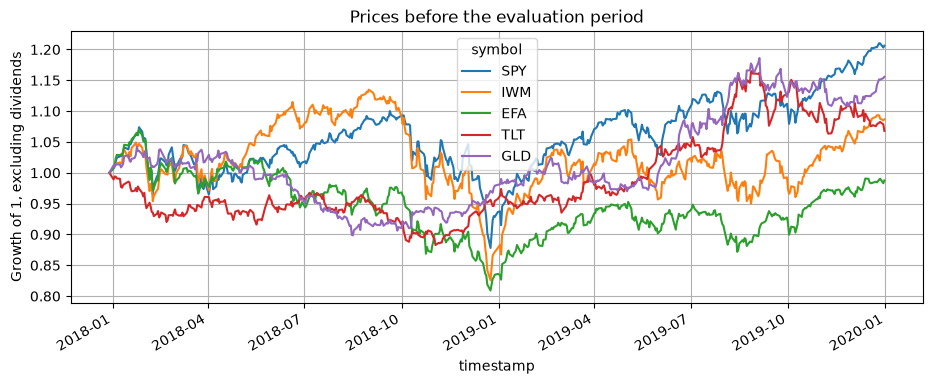

In [3]:
training = returns.loc[returns.index < pd.Timestamp(start, tz="UTC")].tail(lookback)

summary = pd.DataFrame({
    "annualized sample mean": 252 * training.mean(),
    "annualized volatility": np.sqrt(252) * training.std(),
    "daily 95% expected shortfall": [
        risk.expected_shortfall(-training[symbol].to_numpy(), 0.95)
        for symbol in symbols
    ],
})
display(summary.round(4))
display(training.corr().round(2))

(prices.loc[training.index] / prices.loc[training.index[0]]).plot(
    title="Prices before the evaluation period", ylabel="Growth of 1, excluding dividends",
)
plt.show()

For Markowitz, we minimize $-\hat\mu^T w + (10/2) w^T\hat\Sigma w$ using the ordinary sample estimates. For mean–CVaR, we minimize

$$-\hat\mu^T w + \rho \|L^T w\|_2 + 0.2\,\mathrm{CVaR}_{0.95}(-Rw), \qquad LL^T = \hat\Sigma / n.$$

The extra term protects against an ellipsoid of uncertain means. We set $\rho=2$; it is a modeling choice, not a calibrated confidence guarantee. Serial dependence can make $\hat\Sigma/n$ too optimistic. CVaR itself remains empirical: it cannot anticipate a loss missing from the sample.

Both optimizers are long-only, fully invested before the cash reserve, and capped at 40% per fund. The risk coefficients have different units and do not imply equal risk. Equal weight gets the same funds, execution, and cash reserve.

In [4]:
def allocation(sample, method, radius=2.0):
    values = sample.to_numpy()
    mean = values.mean(axis=0)
    covariance = np.cov(values, rowvar=False)
    count = values.shape[1]

    if method == "1/N":
        return np.full(count, 1 / count)

    if method == "Markowitz":
        problem = optimization.QuadraticProgram(
            linear=-mean,
            quadratic=10 * covariance,
            equality=np.ones((1, count)),
            target=[1],
            lower_bounds=0,
            upper_bounds=0.4,
        )
        result = optimization.solve(problem, optimization.ConvexSolver("CLARABEL"))
    elif method == "Robust mean-CVaR":
        mean_uncertainty = robust.Ellipsoid(
            mean, np.linalg.cholesky(covariance / len(values)), radius=radius,
        )
        result = robust.mean_cvar(
            values, ambiguity=mean_uncertainty, aversion=0.2,
            level=0.95, upper_bounds=0.4, solver="CLARABEL",
        )
    else:
        raise ValueError(f"Unknown allocation method: {method}")

    if result.max_violation is None or result.max_violation > 1e-8:
        raise RuntimeError(f"Allocation failed feasibility check: {result}")
    return result.solution


methods = ("1/N", "Markowitz", "Robust mean-CVaR")
initial_weights = pd.DataFrame({
    method: allocation(training, method) for method in methods
}, index=symbols)

display(initial_weights.round(3))
display(pd.DataFrame({
    f"radius={radius}": allocation(training, "Robust mean-CVaR", radius=radius)
    for radius in (0, 1, 2, 4)
}, index=symbols).round(3))

,1/N,Markowitz,Robust mean-CVaR
SPY,0.2,0.4,0.142
IWM,0.2,0.0,0.180
EFA,0.2,0.0,0.000
TLT,0.2,0.2,0.400
GLD,0.2,0.4,0.278


,radius=0,radius=1,radius=2,radius=4
SPY,0.132,0.132,0.142,0.144
IWM,0.203,0.203,0.180,0.178
EFA,0.000,0.000,0.000,0.000
TLT,0.397,0.397,0.400,0.400
GLD,0.268,0.268,0.278,0.278


Now put those allocations inside a strategy. On the first exchange session of each month, it estimates the portfolio from the previous 504 returns. The data provider publishes yesterday's daily bar at today's open. The standard replay assumes zero latency at that open, with modeled costs; there is no fill at yesterday's known close.

`TargetWeightStrategy` sizes whole shares, keeps 2% cash, sells before buying, and waits for actual sale proceeds. The second leg can therefore take another session. Targets stay fixed until the next monthly decision. We record the input cutoff and desired weights so the timing and allocations can be inspected.

In [5]:
class MonthlyPortfolio(cx.TargetWeightStrategy):
    def __init__(self, method):
        self.method = method
        self.decisions = []
        self.metadata = cx.StrategyMetadata(method)
        self.contract = cx.StrategyContract(
            instruments=symbols,
            warmup_sessions=lookback + 1,
            subscriptions=(
                cx.BarSubscription(symbols, "1 day"),
                cx.EventSubscription(cx.Timer, schedule=cx.SessionSchedule(
                    "portfolio", "rebalance", start=date.fromisoformat(start),
                    frequency="monthly", at="open",
                )),
                cx.EventSubscription(cx.Rejection),
                cx.EventSubscription(cx.OrderUpdate),
            ),
        )
        super().__init__(
            self.choose_weights, cash_buffer=Decimal("0.02"),
            cost_bps=10, commission_per_order=1,
            max_price_age=timedelta(days=5),
        )

    def choose_weights(self, context):
        observed = pd.DataFrame({
            symbol: {
                bar.end: float(bar.close)
                for bar in context.history[symbol]
                if bar.end < context.time
            }
            for symbol in symbols
        }).sort_index()

        sample = observed.pct_change(fill_method=None).dropna().tail(lookback)
        if len(sample) != lookback or observed.tail(lookback + 1).isna().any().any():
            raise ValueError(f"Incomplete estimation window at {context.time}")
        assert sample.index.max() < context.time

        weights = dict(zip(symbols, allocation(sample, self.method)))
        self.decisions.append({
            "time": context.time, "last observation": sample.index.max(), **weights,
        })
        return weights

In [6]:
provider = DataFrameHistoricalProvider(bars, price_basis="split_adjusted_price_return")

async def run_portfolios(execution):
    results, strategies = {}, {}

    for method in methods:
        def factory(method=method):
            strategy = MonthlyPortfolio(method)
            strategies[method] = strategy
            return strategy

        # Separate accounts: each method starts with the same cash.
        results[method] = await cx.Research(start, end).run_async(
            factory, provider=provider, cache=None,
            initial_cash=initial_cash, execution=execution,
        )

    return results, strategies


results, strategies = await run_portfolios("standard")

pd.DataFrame({
    method: {
        "monthly decisions": len(strategies[method].decisions),
        "fills": len(result.fills),
        "rejections": len(strategies[method].rejections),
        "open orders at end": len(result.open_orders),
    }
    for method, result in results.items()
}).T

,monthly decisions,fills,rejections,open orders at end
1/N,72,326,0,0
Markowitz,72,240,0,0
Robust mean-CVaR,72,260,0,0


We measure the executed account, not the target-weight return series. Turnover below is two-way traded notional divided by average equity per year, so a full sale and reinvestment counts twice. Sharpe assumes zero cash interest and zero risk-free return. Expected shortfall is a daily loss statistic, not annualized.

In [7]:
def daily_equity(result):
    frame = pd.DataFrame(result.equity).set_index("time")
    frame.index = pd.to_datetime(frame.index, utc=True).tz_convert("America/New_York")
    daily = frame["equity"].astype(float).groupby(frame.index.date).last()
    daily.index = pd.to_datetime(daily.index)
    return daily


def performance(result):
    equity = daily_equity(result)
    wealth = np.r_[initial_cash, equity.to_numpy()]
    daily = wealth[1:] / wealth[:-1] - 1
    years = len(daily) / 252
    traded = sum(float(fill.price * fill.quantity) for fill in result.fills)

    return {
        "annualized return": (wealth[-1] / initial_cash) ** (1 / years) - 1,
        "annualized volatility": daily.std(ddof=1) * np.sqrt(252),
        "Sharpe (RF=0)": daily.mean() / daily.std(ddof=1) * np.sqrt(252),
        "max drawdown": float(risk.maximum_drawdown(wealth)),
        "daily ES 95%": risk.expected_shortfall(-daily, 0.95),
        "annual two-way turnover": traded / equity.mean() / years,
        "commissions USD": float(result.metrics["fees"]),
    }


report = pd.DataFrame({name: performance(result) for name, result in results.items()}).T
report.round(4)

,annualized return,annualized volatility,Sharpe (RF=0),max drawdown,daily ES 95%,annual two-way turnover,commissions USD
1/N,0.0756,0.1337,0.6125,0.2582,0.0196,0.4385,326.410
Markowitz,0.1147,0.1208,0.9601,0.2164,0.0178,1.1481,241.385
Robust mean-CVaR,0.0740,0.1108,0.7001,0.2587,0.0157,1.1132,261.125


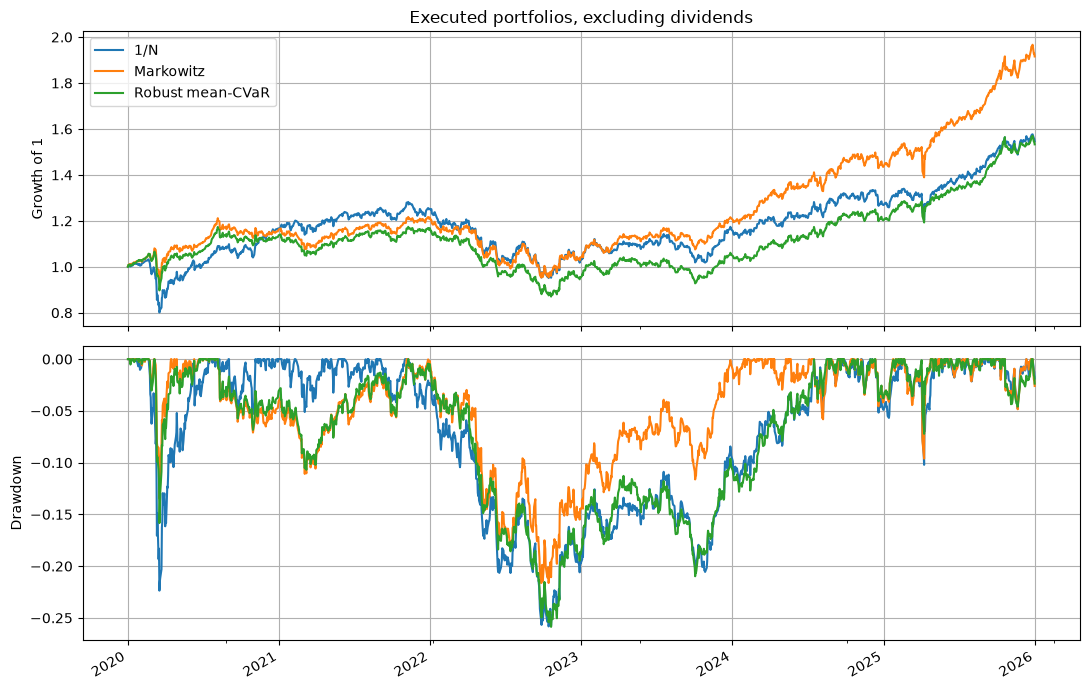

,1/N,Markowitz,Robust mean-CVaR
2020,0.1672,0.1624,0.1373
2021,0.0731,0.0453,0.0273
2022,-0.1789,-0.1440,-0.1849
2023,0.1305,0.1641,0.1054
2024,0.0913,0.1865,0.1421
2025,0.2192,0.3334,0.2750


In [8]:
equity = pd.DataFrame({name: daily_equity(result) for name, result in results.items()})

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
(equity / initial_cash).plot(ax=axes[0], ylabel="Growth of 1", title="Executed portfolios, excluding dividends")

# Include starting cash in the peak, including an initial trading loss.
peaks = equity.cummax().clip(lower=initial_cash)
(equity / peaks - 1).plot(ax=axes[1], ylabel="Drawdown", legend=False)
plt.tight_layout()
plt.show()

year_end = equity.resample("YE").last()
yearly = year_end.pct_change(fill_method=None)
yearly.iloc[0] = year_end.iloc[0] / initial_cash - 1
yearly.index = yearly.index.year
yearly.round(4)

An optimizer can look diversified in the objective and still spend most of its time at the allocation bounds. Let's inspect that rather than infer it from the equity curve. These are desired weights before cash and integer-share rounding; fills and account equity above reflect what actually traded.

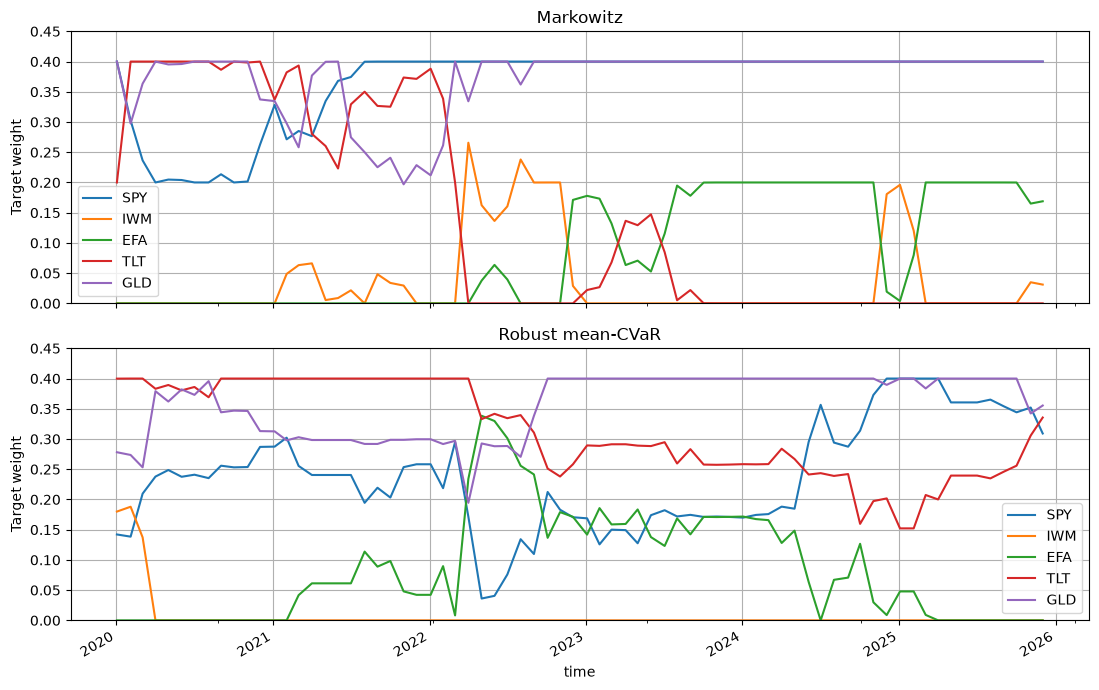

,time,last observation,SPY,IWM,EFA,TLT,GLD
0,2020-01-02 14:30:00+00:00,2019-12-31 21:00:00+00:00,0.142083,1.799496e-01,4.257824e-10,0.399856,0.278111
1,2020-02-03 14:30:00+00:00,2020-01-31 21:00:00+00:00,0.138478,1.879468e-01,4.729835e-11,0.400000,0.273575
2,2020-03-02 14:30:00+00:00,2020-02-28 21:00:00+00:00,0.209590,1.372839e-01,1.804414e-10,0.400000,0.253126
3,2020-04-01 13:30:00+00:00,2020-03-31 20:00:00+00:00,0.237827,2.198755e-10,3.109909e-10,0.383074,0.379098
4,2020-05-01 13:30:00+00:00,2020-04-30 20:00:00+00:00,0.248690,2.372105e-10,2.989997e-10,0.389322,0.361988


In [9]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

for axis, method in zip(axes, methods[1:]):
    decisions = pd.DataFrame(strategies[method].decisions).set_index("time")
    decisions[list(symbols)].plot(ax=axis, title=method, ylim=(0, 0.45))
    axis.set_ylabel("Target weight")

plt.tight_layout()
plt.show()

pd.DataFrame(strategies["Robust mean-CVaR"].decisions).head()

The standard execution preset charges spread, slippage, and commissions. A second run uses the conservative preset, which also delays orders and lowers allowed volume participation. This is a sensitivity check on execution assumptions; it is not a new parameter search.

In [10]:
stress_results, stress_strategies = await run_portfolios("conservative")
stress_report = pd.DataFrame({
    name: performance(result) for name, result in stress_results.items()
}).T

report.to_csv(output / "standard_metrics.csv")
stress_report.to_csv(output / "conservative_metrics.csv")
equity.to_csv(output / "equity.csv")

for method, strategy in strategies.items():
    filename = method.lower().replace(" ", "_").replace("/", "_")
    pd.DataFrame(strategy.decisions).to_csv(output / f"{filename}_decisions.csv", index=False)

pd.concat({
    "standard": report[["annualized return", "max drawdown", "annual two-way turnover"]],
    "conservative": stress_report[["annualized return", "max drawdown", "annual two-way turnover"]],
}, names=["execution", "portfolio"]).round(4)

annualized return  max drawdown  \
execution    portfolio                                           
standard     1/N                          0.0756        0.2582   
             Markowitz                    0.1147        0.2164   
             Robust mean-CVaR             0.0740        0.2587   
conservative 1/N                          0.0762        0.2574   
             Markowitz                    0.1123        0.2115   
             Robust mean-CVaR             0.0731        0.2529   

                               annual two-way turnover  
execution    portfolio                                  
standard     1/N                                0.4385  
             Markowitz                          1.1481  
             Robust mean-CVaR                   1.1132  
conservative 1/N                                0.4365  
             Markowitz                          1.1564  
             Robust mean-CVaR                   1.1140

In this run, robust mean–CVaR reduces daily expected shortfall relative to equal weight, but its maximum drawdown is slightly worse. It also loses more in 2022. Markowitz earns the highest price return here, despite its fragile sample-mean estimates. That is a useful reminder that robustness is protection against a specified uncertainty set, not a guarantee of better realized performance.

The conservative 1/N run slightly improves return; that preset changes trade timing as well as costs.

This example still leaves important work before investing: dividend and cash-interest accounting, a broader asset universe, parameter sensitivity on a separate development period, and genuinely forward performance. In particular, do not use the price-return ranking here to choose between income-producing funds and gold. The saved source snapshot and decision log make it possible to revisit those assumptions without silently changing the sample.